## Project 
139 data set

In [130]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
import scipy.stats as stats
from sklearn import preprocessing
from IPython.display import display
sns.set_theme(style="whitegrid")

In [131]:
filename_1 = "data/gateways.csv"
filename_2 = "data/readings.csv"
filename_3 = "data/units.csv"
def identify_outliers(a):
    lower = a.quantile(0.25) - 1.5 * stats.iqr(a)
    upper = a.quantile(0.75) + 1.5 * stats.iqr(a)
    
    return a[(a > upper) | (a < lower)]

In [132]:
data_1 = pd.read_csv(filename_1, 
                   sep=';', index_col=13)
data_1.head(20)
#data_1.iloc[1999:2020] # id_unit from 2000 to end are NaN

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
gateway_id,,,,,,,,,,,,,
GW-00000,2024-04-08,"10/03/2023, 00:00:00",-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
GW-00001,"11/07/2024, 00:00:00","07/11/2016, 00:00:00",-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
GW-00002,"10/02/2024, 00:00:00","05/04/2016, 00:00:00",-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
GW-00003,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
GW-00004,03 Aug 2024,2024/03/14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90
GW-00005,"10/20/2024, 00:00:00",2020-12-05,-8.31845,63,f9:c5:95:48:1e:bd,v2.7.0,-81.4,41.40283,Pacheco,NODE-7,1891.0,Lisa Burns,142.92.8.43
GW-00006,2024-08-10,"09/30/2023, 00:00:00",-9.11759,57,1e:d2:90:d0:ab:51,v3.4.1,-73.5,39.66395,Paiva Leite Lda.,NODE-9,963.0,Michael Cook,158.92.33.60
GW-00007,2024/04/24,2023-11-12,-9.10634,18,68:01:b8:49:d6:fa,v3.4.1,-74.1,40.13607,Melo,GWX-300,22.0,Etta Zahn-Briemer,100.140.32.72
GW-00008,"12/25/2024, 00:00:00","12/01/2016, 00:00:00",-7.62037,56,7e:36:3b:b5:94:21,v2.7.0,-63.1,39.32954,Pinheiro,GWX-300,1288.0,Anneli Kambs,14.255.71.253


gateway_id - Textual - maybe change to numerical(remove GW from start)

seen_last - Time-series

install_date - Time-series

lon - Numerical(continuous)

idDeport - Discrete

macAddress - Textual ? - cant decide same as ip

versionFirmware - Categorical

signal_dbm - Numerical(continuous)

lat - Numerical(continuous)

Vendor - Categorical

hardware_model - Categorical

id_unit - Numerical(continuous) - change to discrete (all nums have .0) / from 2000 to end are NaN - problem? 

Technician - Categorical(nominal)

ipv4 - Textual ? - cant decide

In [133]:
data_2 = pd.read_csv(filename_2, 
                    sep='\t')
data_2.head(20)

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
0,U00078,24 Sep 2023,2.91072,17.08727,63.17362,10.42780,5.53225,24.90723,5.49963,0
1,U01922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,U00548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
3,U01551,21 Mar 2023,5.12227,21.50330,63.91073,7.86316,1.66650,22.98348,5.09449,1
4,U00298,04 Oct 2023,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0
5,U01522,12 Dec 2023,2.47593,NaN,63.34515,8.66470,5.10853,27.65622,5.79981,1
6,U00748,2023/04/23,6.60443,18.84023,40.67046,8.61937,NaN,25.53233,3.43388,1
7,U00565,2023/03/24,6.48482,26.42038,52.23038,8.45314,1.85331,26.09878,7.24156,0
8,U00588,"01/02/2023, 14:07:00",6.63109,NaN,60.44142,9.34893,3.28290,28.68901,16.55528,1
9,U01188,2023-03-17,4.51353,45.42224,57.41512,8.61459,2.45468,33.13947,8.77440,1


id_unit - Categorical(nominal) - maybe change to numerical(remove U from start because units table has numerical id)

cycle_ts - Time-series

currentMotor - Numerical(continuous)

dp_filter - Numerical(continuous)

oilTemperature - Numerical(continuous)

presure_reservoir - Numerical(continuous)

rmsVibration - Numerical(continuous)

Flowmeter - Numerical(continuous)
 
dischargeDewpoint - Numerical(continuous)

Failure - Categorical(Boolean)

In [134]:
data_3 = pd.read_csv(filename_3, 
                    sep=',',index_col=5
                    )
data_3.head(20)

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
id_unit,,,,,,
1,97,light,2022,7263.7,"09/23/2021, 00:00:00",GQ-0521-56531
2,81,heavy,2023,6053.4,2020-05-07,HN-5203-27688
3,56,light,2023,4921.4,2021/06/04,QC-5243-50182
4,53,3,2018,21803.6,25 Apr 2021,TC-5483-81500
5,54,normal,2020,15730.5,"08/13/2024, 00:00:00",XO-0640-55128
6,49,normal,2024,2672.6,07 Apr 2023,NL-5523-44373
7,54,normal,2017,26298.5,2021-12-02,GM-2661-34290
8,5,light,2019,17581.9,2015/05/15,DE-2078-95757
9,25,L,2022,9111.4,15 Jun 2018,MC-2132-88338


id_unit - Numerical

idDeport - Numerical

duty_class - Categorical - change category names (can see diff names for 1 category)

year_commision - Numerical - not sure its ok

service_hours - Numerical(Continuous)

overhaul_last - Time-series

serial_number - Textual

In [135]:
data_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16000 entries, GW-00000 to GW-15999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   seen_last        16000 non-null  object 
 1   install_date     16000 non-null  object 
 2   Lon              16000 non-null  float64
 3   idDepot          16000 non-null  int64  
 4   macAddress       16000 non-null  object 
 5   versionFirmware  16000 non-null  object 
 6   signal_dbm       16000 non-null  float64
 7   lat              16000 non-null  float64
 8   Vendor           16000 non-null  object 
 9   hardware_model   16000 non-null  object 
 10  id_unit          2000 non-null   float64
 11  Technician       16000 non-null  object 
 12  ipv4             16000 non-null  object 
dtypes: float64(4), int64(1), object(8)
memory usage: 1.7+ MB


id_unit from 2000 to end are NaN - problem?

In [136]:
data_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14052 entries, 0 to 14051
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_unit             14052 non-null  object 
 1   cycle_ts            14052 non-null  object 
 2   currentMotor        14052 non-null  float64
 3   dp_filter           13503 non-null  float64
 4   oilTemperature      14052 non-null  float64
 5   pressure_reservoir  14052 non-null  float64
 6   rmsVibration        13534 non-null  float64
 7   Flowmeter           14052 non-null  float64
 8   dischargeDewpoint   14052 non-null  float64
 9   Failure             14052 non-null  int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 1.1+ MB


dp_filter and 13534 have NaN values - remove / replace

In [137]:
data_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 1 to 2000
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   idDepot          2000 non-null   int64  
 1   duty_class       2000 non-null   object 
 2   year_commission  2000 non-null   int64  
 3   serviceHours     1900 non-null   float64
 4   overhaul_last    2000 non-null   object 
 5   serial_number    2000 non-null   object 
dtypes: float64(1), int64(2), object(3)
memory usage: 109.4+ KB


serviceHours - NaN values remove / replace

In [138]:
data_1.describe(include='all')

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
count,16000,16000,16000.000000,16000.000000,16000,16000,16000.000000,16000.000000,16000,16000,2000.000000,16000,16000
unique,1600,9723,NaN,NaN,16000,3,NaN,NaN,38,5,NaN,120,16000
top,2024-08-05,2023-05-31,NaN,NaN,5a:bb:a2:f5:b8:9a,v1.2.5,NaN,NaN,Speer,NODE-9,NaN,Miguel Marques,240.30.225.100
freq,22,7,NaN,NaN,1,5359,NaN,NaN,810,3263,NaN,165,1
mean,NaN,NaN,-7.751588,58.854125,NaN,NaN,-70.170300,40.155156,NaN,NaN,1000.500000,NaN,NaN
std,NaN,NaN,0.891284,34.567290,NaN,NaN,10.006577,0.900882,NaN,NaN,577.494589,NaN,NaN
min,NaN,NaN,-9.299980,0.000000,NaN,NaN,-107.300000,38.600070,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,-8.524577,29.000000,NaN,NaN,-77.000000,39.373440,NaN,NaN,500.750000,NaN,NaN
50%,NaN,NaN,-7.758115,59.000000,NaN,NaN,-70.200000,40.163690,NaN,NaN,1000.500000,NaN,NaN
75%,NaN,NaN,-6.980605,89.000000,NaN,NaN,-63.400000,40.937605,NaN,NaN,1500.250000,NaN,NaN


In [139]:
data_2.describe(include='all')

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
count,14052,14052,14052.000000,13503.000000,14052.000000,14052.000000,13534.000000,14052.000000,14052.000000,14052.000000
unique,2112,4579,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,U01347,13 Dec 2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,17,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,5.277158,24.073502,50.628361,8.698509,3.083622,27.925684,7.971619,0.118844
std,NaN,NaN,2.893927,11.434870,68.623763,0.601964,1.643651,4.007567,3.507052,0.323617
min,NaN,NaN,0.115880,7.081150,-999.000000,6.500000,0.500000,15.000000,-5.117820,0.000000
25%,NaN,NaN,3.731485,16.246110,46.753862,8.298048,1.936292,25.222520,5.666065,0.000000
50%,NaN,NaN,5.127835,21.249320,55.072740,8.696900,2.718050,27.936505,7.972520,0.000000
75%,NaN,NaN,6.643298,28.690820,63.030540,9.102232,3.830090,30.630375,10.308608,0.000000


In [140]:
data_3.describe(include='all')

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
count,2000.000000,2000,2000.000000,1900.000000,2000,2000
unique,NaN,20,NaN,NaN,1842,2000
top,NaN,L,NaN,NaN,"12/10/2021, 00:00:00",EA-4785-20447
freq,NaN,252,NaN,NaN,3,1
mean,54.737500,NaN,2020.343000,14588.644842,NaN,NaN
std,34.325074,NaN,2.547076,8953.209427,NaN,NaN
min,0.000000,NaN,2012.000000,1303.000000,NaN,NaN
25%,24.000000,NaN,2019.000000,8224.525000,NaN,NaN
50%,53.000000,NaN,2021.000000,12343.300000,NaN,NaN
75%,83.000000,NaN,2022.000000,18475.050000,NaN,NaN


## Short report: 

Data are distributed into 3 .csv files(**gateway**, **readings**, **units**). **gateway** file need ';' to separete data and **gateway_id** is used as index. **readings** need '\t' to separete data. **units** need ',' to separate data and **id_unit** is used as index. **readings** and **units** are related becauce readings is information about checkup of unit. Not sure but **gateway** has info about device which is used to checkup or install something on unit. Number of records: **gateway** - 16000; **readings** - 14052; **units** - 2000. **gateway** has 13 attirbutes(float64(4), int64(1), str(8)); **readings** has 10 attributes (float64(7), int64(1), str(2)); **units** has 6 attributes (float64(1), int64(2), str(3)). 

## Important attributes(maybe):
**units**: duty_class; service_hours

**readings**: currentMotor; dp_filter; oilTemperature; pressure_reservoir; rmsVibration; Flowmeter; dischargeDewpoint; Failure

**gateways**: Lon; signal_dbm; hardware_model; lat; versionFirmware; Vendor

In [155]:
data_3.dropna().shape[0]

1900

In [156]:
data_3.isnull().sum()

idDepot              0
duty_class           0
year_commission      0
serviceHours       100
overhaul_last        0
serial_number        0
dtype: int64

In [157]:
data_3[data_3.isnull().any(axis=1)]

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
id_unit,,,,,,
66,86,light,2020,NaN,19 Apr 2021,WJ-1589-63660
76,1,medium,2022,NaN,"09/30/2020, 00:00:00",BQ-8095-74652
130,84,heavy,2020,NaN,2017-02-15,RL-2537-51896
153,24,light,2021,NaN,28 May 2021,YW-4417-33641
162,74,medium,2021,NaN,16 Oct 2016,LN-7120-15596
...,...,...,...,...,...,...
1932,8,light,2020,NaN,"11/09/2020, 00:00:00",EF-9953-30481
1968,44,light,2022,NaN,"03/04/2016, 00:00:00",CA-8817-92790
1994,16,light,2021,NaN,05 Aug 2024,PS-9327-19274


In [158]:
data_3.duty_class.unique()

array(['light', 'heavy', 'medium'], dtype=object)

In [159]:
data_3['duty_class'] = (
    data_3['duty_class']
    .str.strip()
    .replace({
        '1': 'light',
        'L': 'light',
        'light': 'light',

        '2': 'medium',
        'med': 'medium',
        'N': 'medium',
        'normal': 'medium',

        '3': 'heavy',
        'H': 'heavy',
        'heavy': 'heavy'
    })
)

In [160]:
data_3.duty_class.unique()

array(['light', 'heavy', 'medium'], dtype=object)

In [161]:
data_3.groupby('duty_class').size()

duty_class
heavy     510
light     804
medium    686
dtype: int64

In [162]:
data_3.serviceHours.describe()

count     1900.000000
mean     14588.644842
std       8953.209427
min       1303.000000
25%       8224.525000
50%      12343.300000
75%      18475.050000
max      45000.000000
Name: serviceHours, dtype: float64

<Axes: xlabel='serviceHours', ylabel='duty_class'>

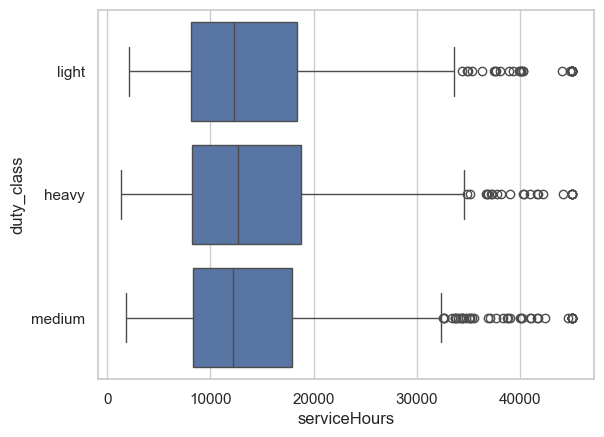

In [163]:
sns.boxplot(data=data_3, x="serviceHours", y="duty_class")

array([[<Axes: title={'center': 'idDepot'}>,
        <Axes: title={'center': 'year_commission'}>],
       [<Axes: title={'center': 'serviceHours'}>, <Axes: >]], dtype=object)

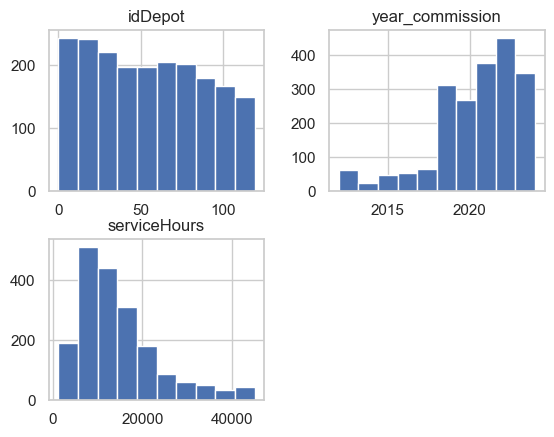

In [164]:
data_3.hist()

1.1.B - Analyza jednotlivych atributov

In [165]:
sensor_cols = ['currentMotor', 'dp_filter', 'oilTemperature', 'pressure_reservoir',
               'rmsVibration', 'Flowmeter', 'dischargeDewpoint']
# ciselne atributy su 7 senzorov + serviceHours (units) + signal_dbm (gateways)
attrs = [(data_2, c) for c in sensor_cols] + [(data_3, 'serviceHours'), (data_1, 'signal_dbm')]
# 10. atribut je kategoria duty_class (units), ta ide zvlast

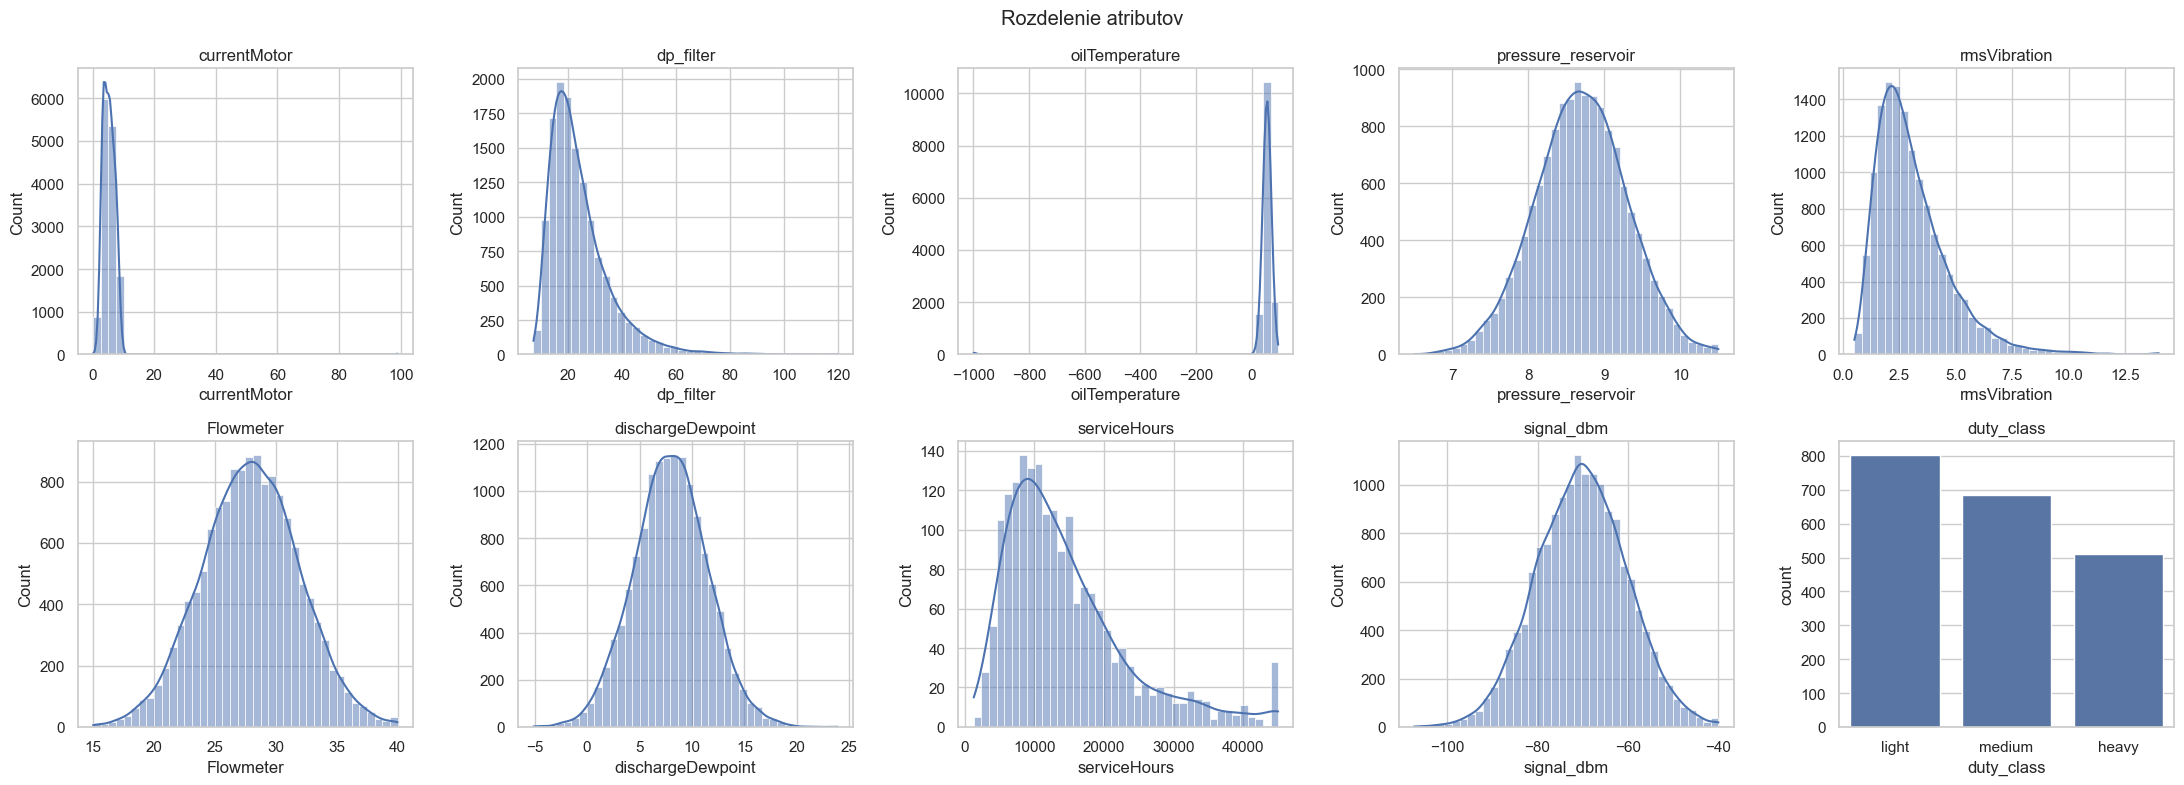

In [166]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.ravel()

for ax, (df_, c) in zip(axes, attrs):
    sns.histplot(df_[c].dropna(), bins=40, kde=True, ax=ax)
    ax.set_title(c)
    
sns.countplot(x='duty_class', data=data_3, order=['light', 'medium', 'heavy'], ax=axes[9])
axes[9].set_title('duty_class')
plt.suptitle('Rozdelenie atributov')
plt.tight_layout(); plt.show()

- currentMotor a oilTemperature maju hlavnu cast hodnot blizko pri sebe, ale osi su natiahnute kvoli osamotenym extremom (99 pri motore, -999 pri oleji), preto graf vyzera ako jediny stlpec,   asi sa jedna o chybne kody
- serviceHours ma stlpec pri 45 000, co vyzera ako strop (hodnoty su orezane na maximum).
- dp_filter, rmsVibration a serviceHours su pravostranne sikme (vacsina hodnot je nizko, dlhy chvost je doprava).
- pressure_reservoir, Flowmeter, dischargeDewpoint a signal_dbm maju zvonovity tvar, su priblizne normalne.
- duty_class nie je uplne vyvazena (light 804, medium 686, heavy 510), ale kazda trieda ma dost zaznamov.

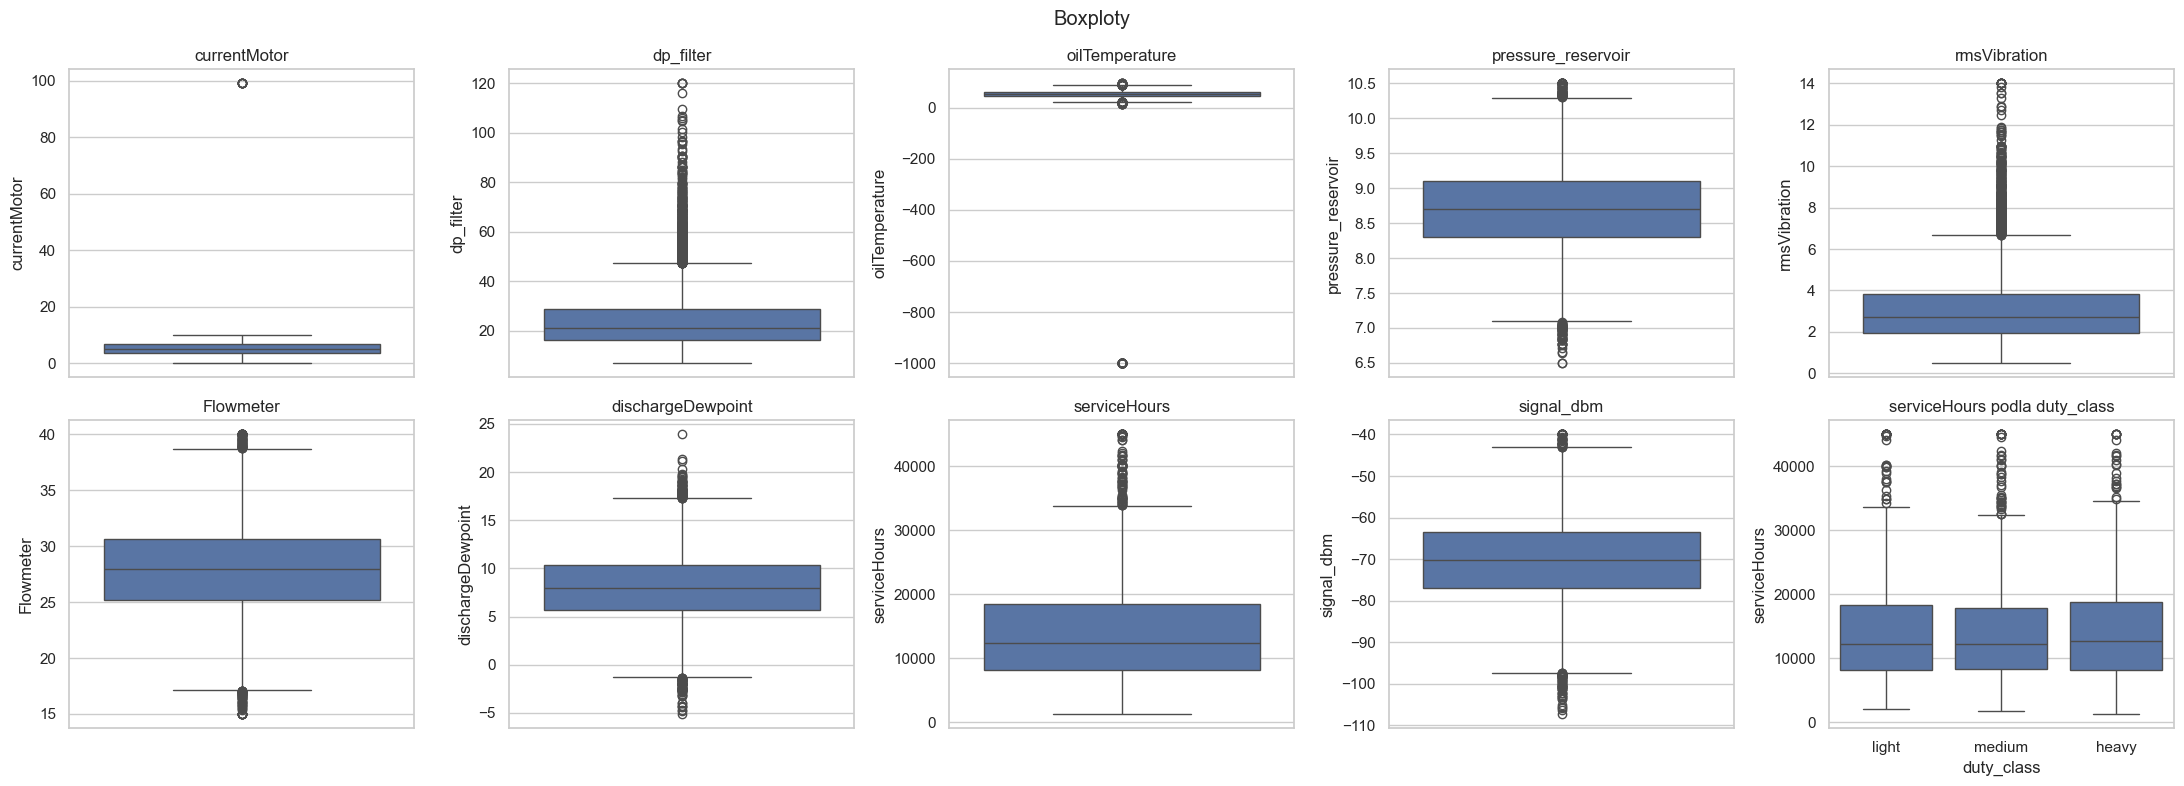

In [167]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.ravel()

for ax, (df_, c) in zip(axes, attrs):
    sns.boxplot(y=df_[c], ax=ax)
    ax.set_title(c)

sns.boxplot(x='duty_class', y='serviceHours', data=data_3, order=['light', 'medium', 'heavy'], ax=axes[9])
axes[9].set_title('serviceHours podla duty_class')
plt.suptitle('Boxploty')
plt.tight_layout(); plt.show()

Boxploty potvrdzuju zistenia z histogramov

In [168]:
print('duty_class:')
display(data_3['duty_class'].value_counts().to_frame('count'))

duty_class:


,count
duty_class,
light,804
medium,686
heavy,510


duty_class uz bol vycisteny (v surovych datach malo 20 roznych zapisov, boli zlucene do 3 tried)

In [ ]:
# Tabulka popisnych statistik
stats_list = []

for df, col in attrs:
    s = df[col]
    s_clean = s.dropna()
    
    q25 = s_clean.quantile(0.25)
    q75 = s_clean.quantile(0.75)
    
    stats_list.append({
        'Attribute': col,
        'Count': len(s),
        'Missing (NaN)': s.isnull().sum(),
        'Mean': round(s_clean.mean(), 2),
        'Std': round(s_clean.std(), 2),
        'Median (50%)': round(s_clean.median(), 2),
        'Min': round(s_clean.min(), 2),
        'Max': round(s_clean.max(), 2),
        'IQR': round(q75 - q25, 2),
        'Skewness': round(s_clean.skew(), 2)
    })

stats_df = pd.DataFrame(stats_list)
display(stats_df)

,Attribute,Count,Missing (NaN),Mean,Std,Median (50%),Min,Max,IQR,Skewness
0,currentMotor,14052,0,5.28,2.89,5.13,0.12,99.0,2.91,19.37
1,dp_filter,14052,549,24.07,11.43,21.25,7.08,120.0,12.44,1.98
2,oilTemperature,14052,0,50.63,68.62,55.07,-999.00,95.0,16.28,-14.77
3,pressure_reservoir,14052,0,8.70,0.60,8.70,6.50,10.5,0.80,-0.02
4,rmsVibration,14052,518,3.08,1.64,2.72,0.50,14.0,1.89,1.65
5,Flowmeter,14052,0,27.93,4.01,27.94,15.00,40.0,5.41,-0.01
6,dischargeDewpoint,14052,0,7.97,3.51,7.97,-5.12,23.9,4.64,0.02
7,serviceHours,2000,100,14588.64,8953.21,12343.30,1303.00,45000.0,10250.52,1.38
8,signal_dbm,16000,0,-70.17,10.01,-70.20,-107.30,-40.0,13.60,0.00


#### Zhodnotenie rozsahov a anomalii:
* Atributy v norme: pressure_reservoir, Flowmeter, dischargeDewpoint, rmsVibration, dp_filter a signal_dbm splnaju ocakavane prevadzkove rozsahy.
* Identifikovane anomalie: oilTemperature: Minimum -999.0 predstavuje chybovy kod snimaca (sentinel). currentMotor: Maximum 99.0 je extrémne odlahla hodnota (outlier medianu 5.13). serviceHours: Maximum 45,000h naznačuje horny strop hodnot v systeme.

In [ ]:
# Kontrola rozsahov a sentinelov
sentinel_candidates = [-999, -99, 99, 999]
range_check = []

for df, col in attrs:
    s = df[col]
    
    # Zistenie vyskytu sentinelov
    found_sentinels = {}
    for val in sentinel_candidates:
        cnt = (s == val).sum()
        if cnt > 0:
            found_sentinels[val] = cnt
            
    range_check.append({
        'Attribute': col,
        'Min': s.min(),
        'Max': s.max(),
        'Sentinels Found': found_sentinels if found_sentinels else "None",
        'NaN Count': s.isnull().sum()
    })

range_df = pd.DataFrame(range_check)
display(range_df)

,Attribute,Min,Max,Sentinels Found,NaN Count
0,currentMotor,0.11588,99.00000,{99: 8},0
1,dp_filter,7.08115,120.00000,None,549
2,oilTemperature,-999.00000,95.00000,{-999: 58},0
3,pressure_reservoir,6.50000,10.50000,None,0
4,rmsVibration,0.50000,14.00000,None,518
5,Flowmeter,15.00000,40.00000,None,0
6,dischargeDewpoint,-5.11782,23.90483,None,0
7,serviceHours,1303.00000,45000.00000,None,100
8,signal_dbm,-107.30000,-40.00000,{-99: 2},0


Analiza rozsahov a sentinelov:
* oilTemperature obsahuje hodnotu -999.0, co je chyba senzora/sentinel. Bude to treba nahradit za NaN. 
* currentMotor ma max hodnotu 99.0, co je odlahly bod oproti 75. percentilu (6.64).
* Chybajuce hodnoty (NaN): dp_filter (549), rmsVibration (518), serviceHours (100) a id_unit v gateways pre ID nad 2000.